# 16. Road Crashes across States

Which states record the highest crash burden and severity?

Primary source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164

Population rates are not travel-exposure rates. Counts depend on reporting and road usage.

This notebook runs the implemented aggregate-indicator workflow. National preview outputs do not complete the primary case study.

In [1]:
from pathlib import Path
import sys
project=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(project.parents[1]))
from src.pipeline import run
status=run(project)
status

Out[0]: 
{'status': 'EXECUTED',
 'scope': 'PRIMARY_NBS_TABLES',
 'utc': '2026-11-21T18:10:36.011433+00:00',
 'rows': 2442,
 'metrics': ['Injured persons', 'Killed persons', 'Total crashes'],
 'primary_case_complete': True,
 'native_bi_validated': False,
 'primary_analysis_executed': True,
 'remaining_limit': 'No mileage or journey exposure denominator is available. Reporting and traffic volumes differ across states.'}


,period,geography,metric,value,unit,source_url,vintage,previous_value,previous_period,absolute_change,relative_change_pct
0,2020-10-01,Abia,Injured persons,146.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
1,2021-01-01,Abia,Injured persons,119.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,146.0,2020-10-01,-27.0,-18.493151
2,2021-04-01,Abia,Injured persons,69.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,119.0,2021-01-01,-50.0,-42.016807
3,2021-07-01,Abia,Injured persons,62.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,69.0,2021-04-01,-7.0,-10.144928
4,2021-10-01,Abia,Injured persons,57.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,62.0,2021-07-01,-5.0,-8.064516
5,2022-01-01,Abia,Injured persons,144.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,57.0,2021-10-01,87.0,152.631579
6,2022-04-01,Abia,Injured persons,107.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,144.0,2022-01-01,-37.0,-25.694444
7,2022-07-01,Abia,Injured persons,101.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,107.0,2022-04-01,-6.0,-5.607477
8,2022-10-01,Abia,Injured persons,89.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,101.0,2022-07-01,-12.0,-11.881188
9,2023-01-01,Abia,Injured persons,45.0,persons,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,89.0,2022-10-01,-44.0,-49.438202


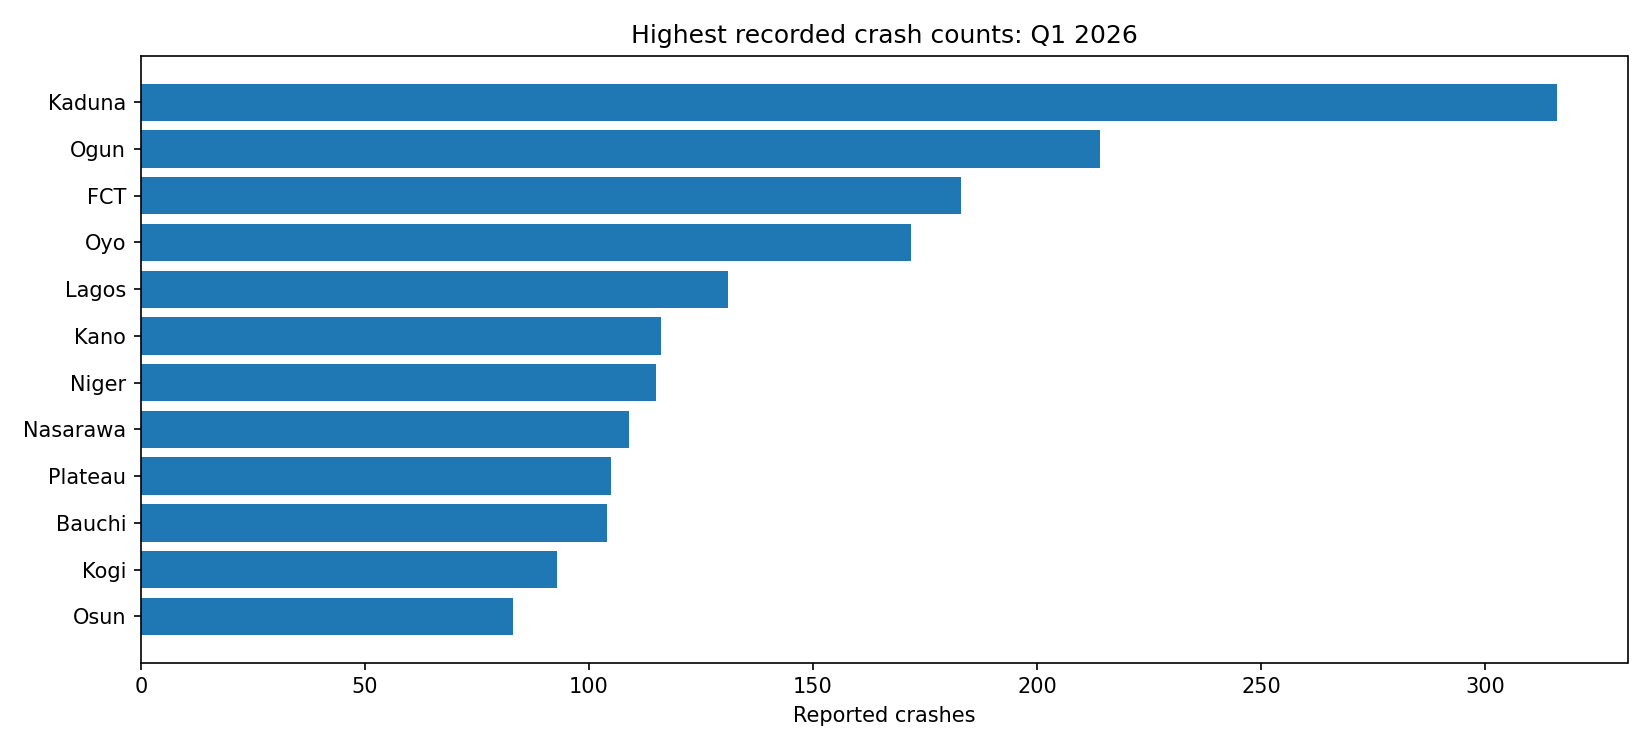

In [2]:
import pandas as pd
from IPython.display import display, Image
if status['status']=='EXECUTED':
    display(pd.read_csv(project/'outputs/analysis.csv').head(25))
    display(Image(filename=str(project/'outputs/trend.png')))
else:
    print(status['reason'])

In [3]:
display(pd.read_csv(project/'outputs/primary_analysis.csv').head(20))
print((project/'reports/RESULTS.md').read_text())

# Road Crashes across States: primary NBS analysis

Kaduna recorded the largest crash count in Q1 2026: 316. This is a count ranking, not a road-user risk ranking.

## Evidence and validation
22 quarters × 37 states/FCT = 814 state-quarter records. All eight state-count columns reconcile to source national totals in every quarter. Severity categories and casualty components reconcile for every state-quarter. The latest-quarter factor columns separately reconcile to published national totals. The adapter records source hashes and exact workbook rows.

## Methods
SQL is in sql/primary_analysis.sql. Source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164/download/1405. Data tables and a balanced-period seasonality comparison are exported in outputs/.

![Primary chart](../outputs/trend.png)

## Limits
No mileage or journey exposure denominator is available. Reporting and traffic volumes differ across states.

## Decision use
Use counts to select locations or periods for a more 

,state,crashes,deaths,injuries,fatal_crash_percentage,deaths_per_100_crashes
0,Kaduna,316.0,198.0,1154.0,31.329114,62.658228
1,Ogun,214.0,87.0,496.0,22.429907,40.654206
2,FCT,183.0,43.0,306.0,20.765027,23.497268
3,Oyo,172.0,48.0,455.0,20.348837,27.906977
4,Lagos,131.0,39.0,231.0,19.847328,29.770992
5,Kano,116.0,51.0,417.0,22.413793,43.965517
6,Niger,115.0,52.0,480.0,25.217391,45.217391
7,Nasarawa,109.0,30.0,245.0,17.431193,27.522936
8,Plateau,105.0,27.0,275.0,12.380952,25.714286
9,Bauchi,104.0,64.0,532.0,26.923077,61.538462


## Interpretation
Review changes within each metric and unit separately. Changes span previous available observations, not necessarily one year. Percentage-point changes and relative percentage changes are different. No causal inference is made. Survey-design uncertainty is not estimated by this aggregate pipeline.